### Loading Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

### Data Preprocessing

In [2]:
#Generating Synthetic Data
X, y_true = make_blobs(n_samples=600, centers=4, n_features=2, cluster_std=1.15, random_state=42)

data = pd.DataFrame(X, columns=["Feature 1", "Feature 2"])
data.head()

,Feature 1,Feature 2
0,-7.769485,-8.311463
1,-6.550882,-6.495484
2,-4.964332,-5.713584
3,-4.235894,-7.297374
4,4.752206,1.084208


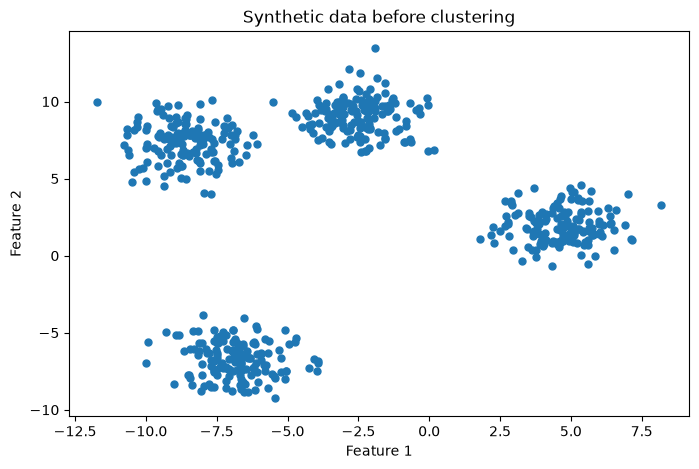

In [3]:
#Visualizing Data
plt.figure(figsize=(8, 5))
plt.scatter(data["Feature 1"], data["Feature 2"], s=25)

plt.title("Synthetic data before clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

plt.show()

### Deciding n_cluster

In [4]:
#Calculating Silhouette Score and Inertia
inertias = []
silhouette_scores = []

for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=42)
    labels = model.fit_predict(X)

    inertias.append(model.inertia_)
    silhouette_scores.append(silhouette_score(X, labels))

#Creating Report
results = pd.DataFrame({
    "Number of Clusters (K)": list(range(2, 11)),
    "Inertia": inertias,
    "Silhouette Score": silhouette_scores
})
results.round(4)

,Number of Clusters (K),Inertia,Silhouette Score
0,2,20113.9070,0.5410
1,3,4524.0971,0.7399
2,4,1528.7309,0.7564
3,5,1404.3569,0.6398
4,6,1283.2454,0.5458
5,7,1141.4744,0.4171
6,8,989.9357,0.3377
7,9,897.0207,0.3517
8,10,819.9500,0.3462


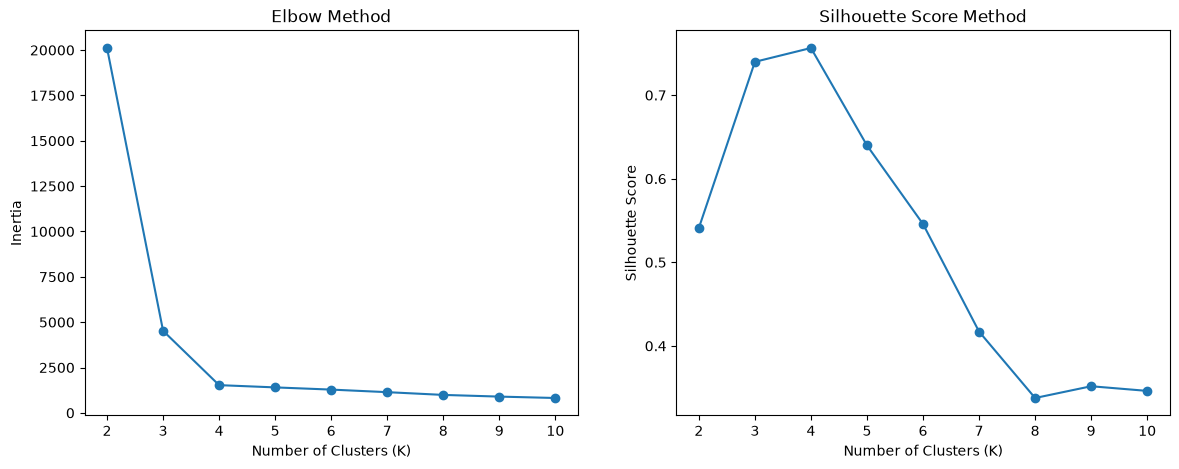

In [6]:
#Plotting Curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

#Elbow Curve
axes[0].plot(list(range(2, 11)), inertias, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia")

#Silhouette Curve
axes[1].plot(list(range(2, 11)), silhouette_scores, marker="o")
axes[1].set_title("Silhouette Score Method")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")

plt.show()

In [7]:
# Suggest K with the highest silhouette score
n = int(results.loc[results["Silhouette Score"].idxmax(), "Number of Clusters (K)"])
print(f"n_clusters highest Silhouette Score: {n}")
print(f"n_clusters after which graph flattens: {n}")

n_clusters highest Silhouette Score: 4
n_clusters after which graph flattens: 4


### Training and Visualizing Model

In [8]:
#Training Model
kmeans = KMeans(n_clusters=n, random_state=42)

data["Cluster"] = kmeans.fit_predict(X)
centers = kmeans.cluster_centers_

print("Inertia:", round(kmeans.inertia_, 2))
print("Silhouette score:", round(silhouette_score(X, data["Cluster"]), 3))

Inertia: 1528.73
Silhouette score: 0.756


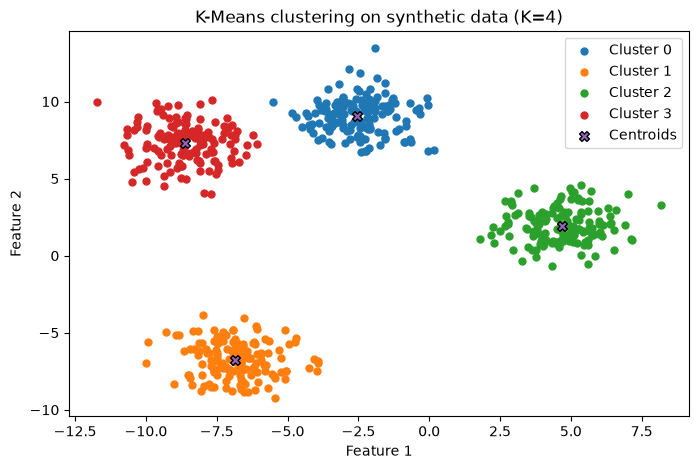

In [9]:
#Visualizing Sepration
plt.figure(figsize=(8, 5))

for cluster_id in sorted(data["Cluster"].unique()):
    part = data[data["Cluster"] == cluster_id]
    plt.scatter(part["Feature 1"], part["Feature 2"], s=25, label=f"Cluster {cluster_id}")
    
plt.scatter(centers[:, 0], centers[:, 1], marker="X", s=50, edgecolor="black", label="Centroids")
plt.title("K-Means clustering on synthetic data (K=4)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()

plt.show()

### Inspecting Custers

In [10]:
print("Cluster sizes:")
display(data["Cluster"].value_counts().sort_index().rename("Number of points").to_frame())

print("\nCluster means:")
display(data.groupby("Cluster")[["Feature 1", "Feature 2"]].mean().round(2))

Cluster sizes:


,Number of points
Cluster,
0,149
1,150
2,150
3,151



Cluster means:


,Feature 1,Feature 2
Cluster,,
0,-2.53,9.04
1,-6.85,-6.74
2,4.67,1.93
3,-8.62,7.34
